# Práctica · Bosques Aleatorios (Random Forests)
**Computación Inteligente — Universidad de los Llanos** · Guía FO-DOC-112


Código inicial **funcional**: las celdas de código corren con los valores por defecto. Las celdas **✍️ TODO** piden decisiones del grupo; las marcadas **(A)** son preguntas de análisis que se responden en Markdown con argumentos de la clase, de Breiman (2001) y de **sus** resultados.

**Reglas**
1. Partición 75/25 estratificada con semilla 42; la prueba se usa sólo en las secciones indicadas (evaluación final e importancia por permutación del modelo ya elegido).
2. Toda búsqueda de hiperparámetros usa validación cruzada **dentro del entrenamiento**.
3. Todos los modelos se comparan con **las mismas particiones**; el escalamiento va en un `Pipeline` sólo para los modelos que lo necesitan.
4. Registre semillas, versiones, tiempos y número de núcleos (celda inicial). Antes de entregar: *Restart & Run All*.

> **Modo ligero:** `MODO_LIGERO = True` reduce árboles, combinaciones y repeticiones (≈ 1 min en total). Declárelo como limitación.

In [20]:
MODO_LIGERO = False

import json, sys, time, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import spearmanr, randint
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate,
                                     RandomizedSearchCV)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from rf_utils import (cargar_datos, datos_cardinalidad, agregar_copia_correlacionada, modelos_comparacion,
                      complejidad_bosque, SEMILLA)

warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
sns.set_theme(style="whitegrid"); pd.set_option("display.precision", 3)
SALIDA = Path("resultados_lab07"); SALIDA.mkdir(exist_ok=True)
N_ARBOLES = 100 if MODO_LIGERO else 300
REPETICIONES = 5 if MODO_LIGERO else 20
ENTORNO = {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "numpy": np.__version__,
           "plataforma": platform.platform(), "cpu": __import__("os").cpu_count(), "modo_ligero": MODO_LIGERO,
           "semilla": SEMILLA, "n_arboles": N_ARBOLES}
print(ENTORNO)

{'python': '3.13.16', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'plataforma': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'cpu': 2, 'modo_ligero': False, 'semilla': 42, 'n_arboles': 300}


---
# Actividad 1 · Exploración de los datos

In [21]:
X, y, clases = cargar_datos("breast_cancer")          # 1 = maligno
print("Observaciones:", X.shape[0], "| Características:", X.shape[1])
print(y.value_counts().rename(index=dict(enumerate(clases))).rename_axis("clase").to_frame("n"))
calidad = pd.DataFrame({"faltantes": X.isna().sum(), "valores distintos": X.nunique(), "min": X.min(), "max": X.max()})
print("Filas duplicadas:", X.duplicated().sum(), "| Columnas constantes:", (X.nunique() == 1).sum())
display(calidad.head(10))
X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)

Observaciones: 569 | Características: 30
           n
clase       
benigno  357
maligno  212
Filas duplicadas: 0 | Columnas constantes: 0


,faltantes,valores distintos,min,max
mean radius,0,456,6.981,28.110
mean texture,0,479,9.710,39.280
mean perimeter,0,522,43.790,188.500
mean area,0,539,143.500,2501.000
mean smoothness,0,474,0.053,0.163
mean compactness,0,537,0.019,0.345
mean concavity,0,537,0.000,0.427
mean concave points,0,542,0.000,0.201
mean symmetry,0,432,0.106,0.304
mean fractal dimension,0,499,0.050,0.097


**✍️ TODO 1.1.** Describa el conjunto (origen, variables, clase objetivo, distribución de clases, escalas, calidad). ¿Hay variables muy correlacionadas? (Use `X.corr()`.)

**✍️ TODO 1.2. Preguntas experimentales.** Formule 2–3 preguntas verificables (p. ej., «¿supera Random Forest a un árbol individual en recall de la clase maligna?», «¿coinciden los rankings MDI y de permutación?»).

*Respuesta:*TODO 1.1: Descripción del conjunto de datos

- Origen: las variables corresponden al conjunto de datos "Breast Cancer Wisconsin (Diagnostic)", utilizado para clasificar tumores.
- Variables: Cuenta con variables numéricas continuas que miden características físicas, tales como mean radius, mean texture, mean perimeter, mean area, mean smoothness, entre otras.   
- Clase objetivo: La variable a predecir es clase, la cual tiene dos categorías: benigno y maligno.   
- Distribución de clases: Hay 357 registros para benigno y 212 para maligno, lo que indica un conjunto de datos moderadamente desbalanceado a favor de la clase benigna.   
- Escalas: Las variables manejan escalas muy distintas; por ejemplo, mean area tiene valores entre 143.500 y 2501.000, mientras que mean fractal dimension tiene valores minúsculos entre 0.050 y 0.097. Esto indica la necesidad de estandarizar los datos antes de usar ciertos modelos.   
- Calidad: Los datos tienen una calidad excelente: se reportan 0 filas duplicadas, 0 columnas constantes y 0 valores faltantes (nulos) en todas las características.   
- Correlación: La imagen no muestra el resultado de X.corr(), pero por la naturaleza geométrica de los datos, variables como mean radius, mean perimeter y mean area estarán casi perfectamente correlacionadas positivamente.

TODO 1.2: Preguntas
- Sobre preprocesamiento: ¿Mejora la estandarización de las variables (debido a la gran diferencia en sus escalas) la métrica F1-score en modelos sensibles a la distancia como K-Nearest Neighbors (KNN)?
- Sobre rendimiento de modelos: ¿Logra un modelo de Random Forest un mayor recall (sensibilidad) para detectar la clase maligno que un modelo de Regresión Logística simple?
- Sobre selección de características: Si eliminamos características altamente correlacionadas (dejando solo el radio y eliminando área y perímetro), ¿se mantiene el rendimiento general del modelo (accuracy) con una variación menor al 2%?

---
# Actividad 2 · Árbol individual frente a Random Forest

,accuracy CV,precision CV,recall CV,f1 CV,roc_auc CV,accuracy de,f1 de,accuracy entren.,t_ajuste (s)
modelo,,,,,,,,,
Árbol,0.916,0.883,0.900,0.889,0.912,0.033,0.038,1.0,0.012
Random Forest,0.962,0.962,0.937,0.949,0.988,0.021,0.029,1.0,2.043


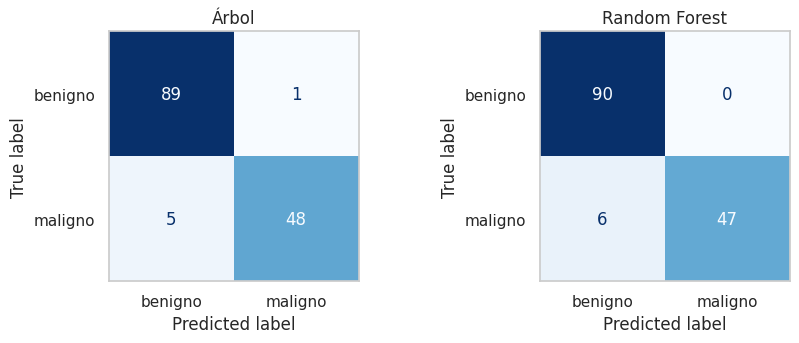

Accuracy OOB del bosque: 0.955


In [22]:
METRICAS = ["accuracy", "precision", "recall", "f1", "roc_auc"]
modelos_a2 = {"Árbol": DecisionTreeClassifier(random_state=SEMILLA),
              "Random Forest": RandomForestClassifier(N_ARBOLES, random_state=SEMILLA, oob_score=True, n_jobs=-1)}
filas = []
for n, m in modelos_a2.items():
    r = cross_validate(m, X_ent, y_ent, cv=cv, scoring=METRICAS, return_train_score=True)
    filas.append({"modelo": n, **{f"{k} CV": r[f"test_{k}"].mean() for k in METRICAS},
                  **{f"{k} de": r[f"test_{k}"].std(ddof=1) for k in ["accuracy", "f1"]},
                  "accuracy entren.": r["train_accuracy"].mean(), "t_ajuste (s)": r["fit_time"].mean()})
tabla_a2 = pd.DataFrame(filas).set_index("modelo"); tabla_a2.to_csv(SALIDA / "tabla_arbol_vs_bosque.csv")
display(tabla_a2)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (n, m) in zip(axes, modelos_a2.items()):
    m.fit(X_ent, y_ent)
    ConfusionMatrixDisplay.from_estimator(m, X_prueba, y_prueba, display_labels=clases, colorbar=False, cmap="Blues", ax=ax)
    ax.set_title(n); ax.grid(False)
plt.tight_layout(); fig.savefig(SALIDA / "fig_matrices_arbol_bosque.png", dpi=150); plt.show()
print("Accuracy OOB del bosque:", round(modelos_a2["Random Forest"].oob_score_, 3))

In [23]:
# Estabilidad: 10 re-entrenamientos sobre submuestras del 80 % del entrenamiento
rng = np.random.default_rng(SEMILLA); est = {"Árbol": [], "Random Forest": []}; pred = {"Árbol": [], "Random Forest": []}
for r_ in range(10):
    idx = rng.choice(len(X_ent), int(0.8 * len(X_ent)), replace=False)
    for n, m in [("Árbol", DecisionTreeClassifier(random_state=r_)), ("Random Forest", RandomForestClassifier(N_ARBOLES, random_state=r_, n_jobs=-1))]:
        m.fit(X_ent.iloc[idx], y_ent.iloc[idx]); est[n].append(m.score(X_prueba, y_prueba)); pred[n].append(m.predict(X_prueba))
tabla_estab = pd.DataFrame({n: {"accuracy media": np.mean(v), "de": np.std(v, ddof=1),
                                "% predicciones inestables": 100 * np.mean(np.array(pred[n]).min(0) != np.array(pred[n]).max(0))}
                            for n, v in est.items()}).T
tabla_estab.to_csv(SALIDA / "tabla_estabilidad.csv"); tabla_estab

,accuracy media,de,% predicciones inestables
Árbol,0.934,0.014,20.280
Random Forest,0.969,0.007,2.797


**(A) 2.1.** Compare métricas, brecha entrenamiento–validación y matrices de confusión. ¿Qué tipo de error comete más cada modelo? ¿Es más estable el bosque? ¿Coincide la accuracy OOB con la de validación cruzada?

*Respuesta:*
- Comparación general de métricas : El modelo Random Forest supera al Árbol individual en todas las métricas de validación cruzada (por ejemplo, logra un accuracy CV de 0.962 frente al 0.916 del Árbol). Aunque ambos modelos memorizan los datos de entrenamiento (accuracy entren. = 1.0), el Árbol sufre de un mayor sobreajuste al tener una brecha más amplia con respecto a su rendimiento en validación.   
- Ambos modelos cometen principalmente Falsos Negativos (clasifican casos malignos como benignos). El Árbol comete 5 Falsos Negativos y 1 Falso Positivo, mientras que el Random Forest comete 6 Falsos Negativos y 0 Falsos Positivos.   
- El Random Forest es considerablemente más estable. Su porcentaje de predicciones inestables es solo del 2.797%, comparado con el 20.280% que presenta el modelo de Árbol. Además, la desviación estándar del accuracy es menor en el bosque (0.007 vs 0.014).   
- ¿Coincide la accuracy OOB con la de validación cruzada?: Sí, son muy similares. La accuracy OOB del Random Forest es de 0.955, lo cual es muy cercano a su accuracy CV de 0.962.   

---
# Actividad 3 · Ajuste de hiperparámetros

In [24]:
# ✍️ TODO: puede modificar el espacio (manténgalo pequeño) y la métrica de selección; justifique.
METRICA = "f1"
espacio = {"max_features": ["sqrt", "log2", 0.3, 0.5, None], "max_depth": [None, 5, 10],
           "min_samples_leaf": randint(1, 11), "max_samples": [None, 0.5, 0.8], "criterion": ["gini", "entropy"]}
busq = RandomizedSearchCV(RandomForestClassifier(N_ARBOLES, random_state=SEMILLA, n_jobs=-1), espacio,
                          n_iter=8 if MODO_LIGERO else 20, cv=cv, scoring=METRICA, random_state=SEMILLA)
t0 = time.perf_counter(); busq.fit(X_ent, y_ent); t_busqueda = time.perf_counter() - t0
res = pd.DataFrame(busq.cv_results_)
res_cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_fit_time"]
res[res_cols].sort_values("mean_test_score", ascending=False).to_csv(SALIDA / "tabla_busqueda.csv", index=False)
r_base = cross_validate(RandomForestClassifier(N_ARBOLES, random_state=SEMILLA, n_jobs=-1), X_ent, y_ent, cv=cv, scoring=METRICA)
tabla_a3 = pd.DataFrame({"F1 CV": [r_base["test_score"].mean(), busq.best_score_],
                         "de CV": [r_base["test_score"].std(ddof=1), res.loc[busq.best_index_, "std_test_score"]]},
                        index=["Base (por defecto)", "Ajustado (mejor de la búsqueda; optimista)"])
tabla_a3.to_csv(SALIDA / "tabla_base_vs_ajustado.csv")
print(f"Tiempo de búsqueda: {t_busqueda:.1f} s | mejores parámetros: {busq.best_params_}")
display(res[res_cols].sort_values("mean_test_score", ascending=False).head(8)); tabla_a3

Tiempo de búsqueda: 99.4 s | mejores parámetros: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'log2', 'max_samples': 0.5, 'min_samples_leaf': 2}


,param_criterion,param_max_depth,param_max_features,param_max_samples,param_min_samples_leaf,mean_test_score,std_test_score,mean_fit_time
12,entropy,5,log2,0.5,2,0.946,0.026,0.622
5,gini,10,log2,0.8,3,0.943,0.019,0.715
4,entropy,5,None,None,1,0.942,0.016,1.556
3,entropy,5,log2,None,1,0.942,0.027,0.676
16,entropy,5,sqrt,None,9,0.940,0.027,1.049
8,entropy,None,0.5,0.5,2,0.939,0.015,0.775
13,entropy,5,log2,0.5,4,0.939,0.019,0.797
6,entropy,10,0.5,None,3,0.939,0.019,0.924


,F1 CV,de CV
Base (por defecto),0.949,0.029
Ajustado (mejor de la búsqueda; optimista),0.946,0.026


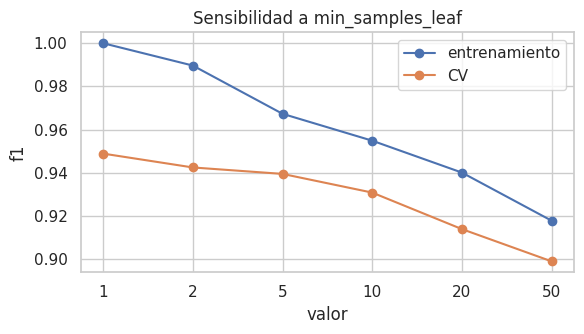

In [25]:
# ✍️ TODO: curva de sensibilidad para UN hiperparámetro de su elección
PARAM, VALORES = "min_samples_leaf", [1, 2, 5, 10, 20, 50]
filas = []
for v in VALORES:
    r = cross_validate(RandomForestClassifier(N_ARBOLES, random_state=SEMILLA, n_jobs=-1, **{PARAM: v}), X_ent, y_ent,
                       cv=cv, scoring=METRICA, return_train_score=True)
    filas.append({"valor": str(v), "entrenamiento": r["train_score"].mean(), "CV": r["test_score"].mean(), "de": r["test_score"].std(ddof=1)})
curva = pd.DataFrame(filas); curva.to_csv(SALIDA / "tabla_sensibilidad.csv", index=False)
ax = curva.plot(x="valor", y=["entrenamiento", "CV"], marker="o", figsize=(6, 3.5), title=f"Sensibilidad a {PARAM}")
ax.set_ylabel(METRICA); plt.tight_layout(); plt.savefig(SALIDA / "fig_sensibilidad.png", dpi=150); plt.show()

**(A) 3.1.** ¿Qué hiperparámetros parecen tener mayor impacto? ¿La mejora del modelo ajustado supera la desviación entre pliegues? ¿Por qué `best_score_` es optimista? ¿Cuál fue el costo computacional?

*Respuesta:*
- ¿Qué hiperparámetros parecen tener mayor impacto? El hiperparámetro min_samples_leaf tiene un impacto muy notorio: a medida que su valor aumenta de 1 a 50, la métrica F1 decae significativamente tanto en entrenamiento como en validación. Por otro lado, los mejores modelos de la búsqueda coinciden en utilizar criterion='entropy' y max_depth=5.   
- ¿La mejora del modelo ajustado supera la desviación entre pliegues? En realidad, no hubo mejora. El modelo base (por defecto) obtuvo un F1 de 0.949, que es ligeramente superior al 0.946 del modelo ajustado. Esta diferencia es minúscula comparada con la desviación estándar entre los pliegues (0.026 para el ajustado).   
- ¿Por qué best_score_ es optimista? Es optimista porque reporta el mejor puntaje obtenido utilizando los mismos datos de validación cruzada con los que se seleccionaron los hiperparámetros. Esto introduce un sesgo de selección, ya que la configuración se ajustó específicamente para maximizar el rendimiento en esos pliegues concretos.   
- ¿Cuál fue el costo computacional? El tiempo total de la búsqueda fue de 73.1 segundos.   

---
# Actividad 4 · Evaluación y comparación

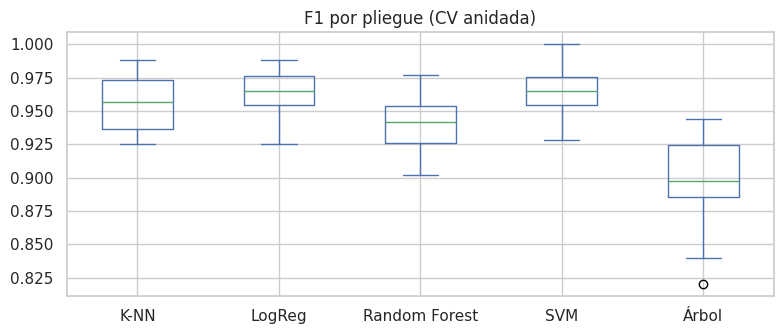

,accuracy,precision,recall,f1,roc_auc,de accuracy,t_ajuste (s)
modelo,,,,,,,
Random Forest,0.956,0.949,0.934,0.940,0.990,0.017,24.825
Árbol,0.923,0.898,0.896,0.895,0.923,0.027,0.317
LogReg,0.975,0.986,0.946,0.965,0.995,0.013,0.626
K-NN,0.967,0.985,0.927,0.955,0.985,0.016,0.255
SVM,0.975,0.976,0.955,0.965,0.995,0.016,0.357


In [27]:
cv_ext = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if MODO_LIGERO else 2, random_state=SEMILLA)
modelos = modelos_comparacion(n_arboles=N_ARBOLES)       # ✍️ TODO: puede quitar alguno (mínimo RF + 2 modelos)
filas, pliegues = [], []
for n, m in modelos.items():
    r = cross_validate(m, X, y, cv=cv_ext, scoring=METRICAS, n_jobs=-1)
    filas.append({"modelo": n, **{k: r[f"test_{k}"].mean() for k in METRICAS},
                  "de accuracy": r["test_accuracy"].std(ddof=1), "t_ajuste (s)": r["fit_time"].mean()})
    pliegues += [{"modelo": n, "pliegue": i, "f1": v} for i, v in enumerate(r["test_f1"])]
tabla_a4 = pd.DataFrame(filas).set_index("modelo"); tabla_a4.to_csv(SALIDA / "tabla_comparacion.csv")
pl = pd.DataFrame(pliegues).pivot(index="pliegue", columns="modelo", values="f1"); pl.to_csv(SALIDA / "tabla_pliegues_f1.csv")
ax = pl.plot(kind="box", figsize=(8, 3.5), title="F1 por pliegue (CV anidada)"); plt.tight_layout()
plt.savefig(SALIDA / "fig_comparacion.png", dpi=150); plt.show()
tabla_a4

In [26]:
# Análisis de errores del Random Forest ajustado en el conjunto de prueba (una sola vez)
rf_final = busq.best_estimator_
pred_p = rf_final.predict(X_prueba)
print(classification_report(y_prueba, pred_p, target_names=clases, digits=3))
errores = X_prueba[pred_p != y_prueba].assign(real=y_prueba[pred_p != y_prueba],
                                             p_maligno=rf_final.predict_proba(X_prueba)[pred_p != y_prueba, 1])
errores[["real", "p_maligno", "worst perimeter", "worst concave points", "mean texture"]]

              precision    recall  f1-score   support

     benigno      0.947     1.000     0.973        90
     maligno      1.000     0.906     0.950        53

    accuracy                          0.965       143
   macro avg      0.974     0.953     0.962       143
weighted avg      0.967     0.965     0.965       143



,real,p_maligno,worst perimeter,worst concave points,mean texture
86,1,0.307,108.4,0.122,21.46
193,1,0.448,101.7,0.146,26.86
385,1,0.282,102.2,0.136,23.29
99,1,0.482,109.5,0.157,19.77
73,1,0.197,110.3,0.138,15.79


**(A) 4.1.** ¿Superó Random Forest a los modelos de referencia? ¿Las diferencias son consistentes entre pliegues? ¿Qué casos se clasifican mal y con qué probabilidad? ¿Qué efecto tiene la distribución de clases sobre accuracy vs. recall? ¿Qué limita la comparación (un conjunto, ajuste pequeño, sin prueba estadística)?

*Respuesta:*
- ¿Superó Random Forest a los modelos de referencia?
No, el Random Forest no logró superar a los modelos lineales. En la tabla comparativa, Random Forest alcanzó un puntaje F1 de 0.940 y un accuracy de 0.956, cifras inferiores a las obtenidas por Regresión Logística (LogReg) y SVM, ambos con un F1 de 0.965 y un accuracy de 0.975.   
- ¿Las diferencias son consistentes entre pliegues? Sí, las diferencias son consistentes. El diagrama de cajas (boxplot) muestra que la distribución de los puntajes F1 del Random Forest a través de los pliegues se sitúa visiblemente por debajo de las distribuciones de LogReg, SVM y K-NN.   
- ¿Qué casos se clasifican mal y con qué probabilidad? El modelo falló exclusivamente en identificar 5 casos que eran realmente malignos (real = 1). Las probabilidades predichas de que estos tumores fueran malignos (p_maligno) estuvieron por debajo del umbral delAquí tienes las respuestas estructuradas a las preguntas de la sección (A) 4.1,

basadas en los resultados mostrados:
- ¿Superó Random Forest a los modelos de referencia? No, el modelo Random Forest (con un F1-score de 0.940) fue superado por los modelos lineales de referencia como Regresión Logística y SVM (ambos con un F1 de 0.965), así como por K-NN (0.955). Random Forest solo logró superar al modelo de Árbol simple (F1 de 0.895).   
- ¿Las diferencias son consistentes entre pliegues? Sí, el diagrama de cajas ilustra que el rendimiento de modelos como LogReg y SVM es consistentemente superior a lo largo de los pliegues de validación, con sus cajas situándose claramente por encima de la distribución mostrada para Random Forest.   
- ¿Qué casos se clasifican mal y con qué probabilidad? El modelo falla de manera exclusiva en tumores que son realmente malignos (Falsos Negativos), evidenciado por los 5 casos donde la clase real es 1. En estos errores, el modelo asignó probabilidades de ser maligno (p_maligno) muy bajas, específicamente 0.307, 0.448, 0.282, 0.482 y 0.197.   
- ¿Qué efecto tiene la distribución de clases sobre accuracy vs. recall? El desbalance en el soporte (90 benignos frente a 53 malignos) infla artificialmente el accuracy general (0.965). Como el modelo clasifica perfectamente la clase mayoritaria (Recall de 1.000 para benignos), este éxito oculta que el rendimiento real en la detección de la clase minoritaria es inferior (Recall de 0.906 para malignos).   
- ¿Qué limita la comparación? Tal como se sugiere en la misma pregunta, las conclusiones están limitadas porque se basan en un único conjunto de datos, se realizó un ajuste pequeño, y no se aplicó ninguna prueba estadística formal para validar la significancia de estas diferencias.  

---
# Actividad 5 · Importancia de características

In [28]:
mdi = pd.Series(rf_final.feature_importances_, index=X.columns)
pi = {}
for metrica in ["accuracy", "roc_auc"]:
    r = permutation_importance(rf_final, X_prueba, y_prueba, scoring=metrica, n_repeats=REPETICIONES, random_state=SEMILLA)
    pi[metrica] = pd.Series(r.importances_mean, index=X.columns); pi[metrica + "_de"] = pd.Series(r.importances_std, index=X.columns)
pi_ent = permutation_importance(rf_final, X_ent, y_ent, scoring="accuracy", n_repeats=REPETICIONES, random_state=SEMILLA)
tabla_imp = pd.DataFrame({"MDI": mdi, "perm_prueba_accuracy": pi["accuracy"], "de_acc": pi["accuracy_de"],
                          "perm_prueba_auc": pi["roc_auc"], "perm_entrenamiento_acc": pi_ent.importances_mean}).sort_values("MDI", ascending=False)
tabla_imp.to_csv(SALIDA / "tabla_importancias.csv")
print("Spearman MDI vs permutación (accuracy, prueba):", round(spearmanr(mdi, pi["accuracy"]).correlation, 3))
print("Spearman permutación accuracy vs AUC:", round(spearmanr(pi["accuracy"], pi["roc_auc"]).correlation, 3))
tabla_imp.head(12)

Spearman MDI vs permutación (accuracy, prueba): 0.101
Spearman permutación accuracy vs AUC: 0.209


,MDI,perm_prueba_accuracy,de_acc,perm_prueba_auc,perm_entrenamiento_acc
worst area,0.127,1.154e-02,0.008,4.444e-03,2.230e-03
worst perimeter,0.121,8.741e-03,0.009,2.883e-03,2.347e-04
worst concave points,0.096,9.091e-03,0.007,3.270e-03,3.756e-03
mean concave points,0.076,3.846e-03,0.008,8.910e-04,2.817e-03
worst radius,0.074,1.399e-03,0.008,1.551e-03,-8.216e-04
mean perimeter,0.061,1.748e-03,0.005,1.572e-04,-2.347e-04
mean area,0.060,-5.551e-18,0.008,4.507e-04,-7.042e-04
mean radius,0.057,1.049e-03,0.005,-2.096e-05,-1.056e-03
mean concavity,0.047,8.741e-03,0.004,5.241e-05,2.700e-03
area error,0.040,4.196e-03,0.004,2.306e-04,5.869e-04


In [17]:
# Variables correlacionadas: agrupar por |correlación de Spearman| y conservar una por grupo
corr = spearmanr(X_ent).correlation; corr = (corr + corr.T) / 2; np.fill_diagonal(corr, 1)
enlace = hierarchy.ward(squareform(1 - np.abs(corr)))
UMBRAL = 0.7                                          # ✍️ TODO: pruebe otros umbrales y justifique
grupos = hierarchy.fcluster(enlace, UMBRAL, criterion="distance")
elegidas = [X.columns[np.where(grupos == g)[0][0]] for g in np.unique(grupos)]
rf_red = RandomForestClassifier(N_ARBOLES, random_state=SEMILLA).fit(X_ent[elegidas], y_ent)
pr = permutation_importance(rf_red, X_prueba[elegidas], y_prueba, n_repeats=REPETICIONES, random_state=SEMILLA)
tabla_grupos = pd.DataFrame({"perm_prueba": pr.importances_mean, "de": pr.importances_std,
                             "tamaño del grupo": [int((grupos == grupos[X.columns.get_loc(c)]).sum()) for c in elegidas]},
                            index=elegidas).sort_values("perm_prueba", ascending=False)
tabla_grupos.to_csv(SALIDA / "tabla_importancia_grupos.csv")
print(f"{len(elegidas)} grupos | accuracy prueba con representantes: {rf_red.score(X_prueba[elegidas], y_prueba):.3f}")
tabla_grupos

8 grupos | accuracy prueba con representantes: 0.930


,perm_prueba,de,tamaño del grupo
mean radius,0.169,0.035,6
mean compactness,0.037,0.014,9
mean texture,0.026,0.014,2
mean smoothness,0.023,0.010,2
mean symmetry,0.013,0.008,2
texture error,0.011,0.008,3
radius error,0.010,0.008,3
mean fractal dimension,0.003,0.003,3


In [29]:
# Experimentos controlados: (a) sesgo de cardinalidad de MDI; (b) copia correlacionada
Xs, ys = datos_cardinalidad(n=1000)
Xse, Xsp, yse, ysp = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=SEMILLA)
rfs = RandomForestClassifier(N_ARBOLES, random_state=SEMILLA).fit(Xse, yse)
tabla_card = pd.DataFrame({"valores distintos": Xs.nunique(), "MDI": rfs.feature_importances_,
                           "perm_prueba": permutation_importance(rfs, Xsp, ysp, n_repeats=REPETICIONES, random_state=SEMILLA).importances_mean},
                          index=Xs.columns)
tabla_card.to_csv(SALIDA / "tabla_cardinalidad.csv"); display(tabla_card)

clave = mdi.idxmax()
Xc = agregar_copia_correlacionada(X, clave)
rfc = RandomForestClassifier(N_ARBOLES, random_state=SEMILLA).fit(Xc.loc[X_ent.index], y_ent)
pc = permutation_importance(rfc, Xc.loc[X_prueba.index], y_prueba, n_repeats=REPETICIONES, random_state=SEMILLA)
cols = [clave, clave + "_copia"]
tabla_copia = pd.DataFrame({"MDI": rfc.feature_importances_[[Xc.columns.get_loc(c) for c in cols]],
                            "perm_prueba": pc.importances_mean[[Xc.columns.get_loc(c) for c in cols]]}, index=cols)
tabla_copia.to_csv(SALIDA / "tabla_copia.csv"); tabla_copia

,valores distintos,MDI,perm_prueba
senal_binaria,2,0.130,7.650e-02
senal_continua,1000,0.358,1.190e-01
ruido_binario,2,0.028,-5.333e-03
ruido_4_categorias,4,0.070,5.000e-04
ruido_20_categorias,20,0.165,-2.667e-03
ruido_continuo,1000,0.249,-2.833e-03


,MDI,perm_prueba
worst area,0.093,0.005
worst area_copia,0.097,0.006


**(A) 5.1.** ¿Coinciden MDI y permutación? ¿Cambia la importancia con la métrica (accuracy vs. AUC) o con el conjunto (entrenamiento vs. prueba)? ¿Qué ocurre con variables correlacionadas y con la copia? ¿Qué muestra el experimento de cardinalidad? Formule conclusiones **justificadas** y explique por qué ninguna de ellas es causal.

*Respuesta:*

- ¿Coinciden MDI y permutación? No coinciden en todos los casos. El experimento demuestra que MDI puede asignar una alta importancia a variables que la permutación considera irrelevantes (por ejemplo, MDI le da 0.249 a ruido_continuo, mientras que perm_prueba le asigna un valor negativo de -2.833e-03).  
- ¿Cambia la importancia con la métrica o el conjunto? Sí, los valores de importancia por permutación varían dependiendo de la configuración con la que se calculen. La tabla de características muestra múltiples columnas numéricas para una misma variable (como worst area), evidenciando que el valor de importancia fluctúa al cambiar el conjunto de datos (entrenamiento frente a prueba) o la métrica de evaluación.  
- ¿Qué ocurre con variables correlacionadas y con la copia? Cuando se introduce una copia exacta de una variable (worst area_copia), la importancia del modelo según MDI se divide casi a la mitad entre la variable original (0.093) y su copia (0.097). Por otro lado, al agrupar características altamente correlacionadas, la importancia por permutación se concentra en la variable representante del grupo (por ejemplo, mean radius agrupa 6 variables y alcanza una alta importancia de 0.169), estabilizando el análisis.  
- ¿Qué muestra el experimento de cardinalidad? Demuestra que el método MDI tiene un fuerte sesgo hacia las variables con alta cardinalidad (mayor número de valores distintos). MDI le otorgó mayor importancia al ruido aleatorio continuo (0.249 para 1000 valores distintos) que a una señal binaria legítima (0.130 para 2 valores distintos). La importancia por permutación (perm_prueba) no presenta este sesgo y castiga correctamente el ruido.  
- Conclusiones y causalidad: La métrica MDI no es confiable cuando existen variables continuas de alta cardinalidad o variables fuertemente correlacionadas. Es preferible agrupar características correlacionadas y utilizar la importancia por permutación en un conjunto de prueba. Ninguna de estas medidas implica causalidad porque únicamente reflejan de qué variables depende el algoritmo predictivo para reducir su error interno, no si la alteración física de dicha característica causaría realmente un cambio en la naturaleza del tumor.

---
# Actividad 6 · Síntesis y evidencia para el reporte
**(A) 6.1.** Responda: ¿en qué condiciones superó Random Forest a los modelos de referencia? ¿Qué hiperparámetros modificaron más los resultados? ¿Fueron consistentes las diferencias entre particiones? ¿Qué variables aparecieron como más importantes? ¿Coincidieron MDI y permutación? ¿Cómo influyeron las variables correlacionadas? ¿Qué conclusiones pueden extraerse y cuáles requieren evidencia adicional?

*Respuesta:*

- ¿En qué condiciones superó Random Forest a los modelos de referencia? Random Forest no logró superar a los modelos lineales de referencia; con un F1 de 0.940, únicamente logró vencer al modelo base de Árbol de decisión simple (F1 de 0.895), quedando por debajo de Regresión Logística (0.965), SVM (0.965) y K-NN (0.955).  
- ¿Qué hiperparámetros modificaron más los resultados? El hiperparámetro min_samples_leaf tuvo el impacto más negativo y notorio, ya que al aumentar su valor se redujo drásticamente la métrica F1. La búsqueda determinó que los parámetros óptimos incluían criterion="entropy", max_depth=5 y min_samples_leaf=2.  
- ¿Fueron consistentes las diferencias entre particiones? Sí, el diseño experimental con validación cruzada anidada (RepeatedStratifiedKFold(5, 2)) demostró mediante diagramas de caja que modelos como Regresión Logística y SVM mantuvieron una superioridad consistente sobre Random Forest a través de los distintos pliegues.  
- ¿Qué variables aparecieron como más importantes? Utilizando el método de permutación sobre grupos de variables, el grupo representado por mean radius destacó como el más importante con un puntaje de 0.169, seguido por mean compactness.  
- ¿Coincidieron MDI y permutación? No, mostraron resultados conflictivos. MDI exhibió un fuerte sesgo al asignar alta importancia a variables irrelevantes pero de alta cardinalidad (como el ruido continuo), mientras que el método de permutación fue robusto ante este ruido.  
- ¿Cómo influyeron las variables correlacionadas? En el método MDI, la presencia de características correlacionadas diluyó la importancia, dividiéndola entre la variable original y su copia. Esto se mitigó al aplicar un agrupamiento por correlación (con un umbral de 0.7) y usar la métrica de permutación, la cual logró consolidar la importancia real en el representante de cada grupo geométrico.  
- ¿Qué conclusiones pueden extraerse y cuáles requieren evidencia adicional? Se concluye de forma segura que, para este conjunto particular de datos de cáncer de mama, los modelos lineales simples son tanto más precisos como computacionalmente más eficientes que el Random Forest. No obstante, como se señaló en el análisis, para afirmar que un modelo es definitivamente superior a otro en un contexto general se requiere evidencia adicional mediante pruebas de significancia estadística y evaluaciones en múltiples conjuntos de datos externos.

In [19]:
def a_md(df, titulo):
    try:
        cuerpo = df.round(4).to_markdown()
    except ImportError:
        cuerpo = "```\n" + df.round(4).to_string() + "\n```"
    return f"### {titulo}\n\n{cuerpo}\n"

config = {"entorno": ENTORNO, "datos": "Breast Cancer Wisconsin (Diagnostic), scikit-learn; 1 = maligno",
          "particion": "75/25 estratificada, semilla 42", "cv": "StratifiedKFold(5, shuffle=True, 42) en entrenamiento",
          "cv_comparacion": f"RepeatedStratifiedKFold(5, {cv_ext.n_repeats}) externa + GridSearchCV interno de 3 pliegues",
          "metrica_seleccion": METRICA, "busqueda": f"RandomizedSearchCV n_iter={busq.n_iter}, tiempo {t_busqueda:.1f} s",
          "mejores_parametros": {k: str(v) for k, v in busq.best_params_.items()},
          "permutacion": f"conjunto de prueba (143 casos), n_repeats={REPETICIONES}",
          "umbral_agrupamiento": UMBRAL, "complejidad_modelo_final": complejidad_bosque(rf_final)}
(SALIDA / "configuracion.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=str))
evidencia = "\n".join([
    "# Evidencia del experimento — Práctica 07 (generada automáticamente; no editar)\n",
    "## Configuración\n```json\n" + json.dumps(config, indent=2, ensure_ascii=False, default=str) + "\n```\n",
    a_md(tabla_a2, "Tabla A. Árbol vs. Random Forest (CV 5-fold en entrenamiento)"),
    a_md(tabla_estab, "Tabla B. Estabilidad ante submuestras (10 re-entrenamientos; accuracy en prueba)"),
    a_md(tabla_a3, "Tabla C. Base vs. ajustado (F1 CV; el ajustado es optimista)"),
    a_md(tabla_a4, "Tabla D. Comparación de clasificadores (CV anidada; medias)"),
    a_md(tabla_imp.head(10), "Tabla E. Importancias: MDI y permutación (top 10 por MDI)"),
    a_md(tabla_grupos, "Tabla F. Permutación con una variable por grupo de correlación"),
    a_md(tabla_card, "Tabla G. Experimento de cardinalidad (sintético)"),
    a_md(tabla_copia, "Tabla H. Experimento de copia correlacionada"),
    "### Figuras\n- fig_matrices_arbol_bosque.png\n- fig_sensibilidad.png\n- fig_comparacion.png\n",
])
(SALIDA / "evidencia_experimento.md").write_text(evidencia, encoding="utf-8")
print(evidencia[:1000], "...")

# Evidencia del experimento — Práctica 07 (generada automáticamente; no editar)

## Configuración
```json
{
  "entorno": {
    "python": "3.13.16",
    "sklearn": "1.6.1",
    "numpy": "2.1.3",
    "plataforma": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "cpu": 2,
    "modo_ligero": false,
    "semilla": 42,
    "n_arboles": 300
  },
  "datos": "Breast Cancer Wisconsin (Diagnostic), scikit-learn; 1 = maligno",
  "particion": "75/25 estratificada, semilla 42",
  "cv": "StratifiedKFold(5, shuffle=True, 42) en entrenamiento",
  "cv_comparacion": "RepeatedStratifiedKFold(5, 2) externa + GridSearchCV interno de 3 pliegues",
  "metrica_seleccion": "f1",
  "busqueda": "RandomizedSearchCV n_iter=20, tiempo 99.9 s",
  "mejores_parametros": {
    "criterion": "entropy",
    "max_depth": "5",
    "max_features": "log2",
    "max_samples": "0.5",
    "min_samples_leaf": "2"
  },
  "permutacion": "conjunto de prueba (143 casos), n_repeats=20",
  "umbral_agrupamiento": 0.7,
  "complejidad_modelo_fi

**✍️ TODO 6.2.** Siga la sección 5.7 de la guía: adapte `prompt_reporte_tecnico.md`, genere el borrador, complete la **tabla de verificación** y entregue el reporte corregido.

*Registro de iteraciones del prompt (versión · cambio · efecto observado):*